# Libraries import and data loading  



In [2]:
#libraries import
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, KFold

import tensorflow as tf
from tensorflow import keras
from keras.callbacks import EarlyStopping
from keras.layers import Dense, Dropout

from functions import *

np.random.seed(111)
tf.random.set_seed(111)

In [3]:
# load data from github 
df = pd.read_csv('https://raw.githubusercontent.com/paq88/Deep-Learning-in-classification-of-common-Carp-intestine-classification/refs/heads/main/Data/Gut_bacteria_merged.csv')
print(f"shape:{df.shape}")
print(df.dtypes.value_counts())
df.head()

shape:(124, 127)
float64    126
object       1
Name: count, dtype: int64


,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df = df.fillna(0)

### Conversion of class variable


Explanation of pond coding

| number | setup | pond numbers | water supplementation | feed suplementation |
|---|---|---|---|---|
|0|control | 8,14,18,24,29|NO|NO|
|1|set 1 | 12,16,19,23,26|Em farma|NO|
|2|set 2 | 10,21,28,30,32|Em farma|EM|
|3|set 3 | 9,13,17,20,27|EM|NO|
|4|set 4 | 11,15,22,25,31|EM|EM|

In [5]:
predictors = df.columns[1:]
print(f"Number of predictors: {len(predictors)}")
predictors

Number of predictors: 126


Index(['d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae',
       'd__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae',
       'd__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae',
       ...
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alterom

In [6]:
df.head()

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
# creating dataset splitted into 5 classes based on the pond 
codes = {0 : [8,14,18,24,29], 1: [12,16,19,23,26], 2 : [10,21,28,30,32], 3 : [9,13,17,20,27], 4 : [11,15,22,25,31]}
codes3 = {0 : [8,14,18,24,29], 1: [12,16,19,23,26,9,13,17,20,27], 2 : [10,21,28,30,32,11,15,22,25,31]}
codes2 = {0 : [8,14,18,24,29,12,16,19,23,26,9,13,17,20,27], 1 : [10,21,28,30,32,11,15,22,25,31]}

df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
df['pond_2'] = df['pond'].apply(lambda x: pond_decoder(x,codes2))


In [8]:
df['pond_5'].value_counts()

pond_5
2    25
4    25
1    25
3    25
0    24
Name: count, dtype: int64

In [9]:
df[predictors]

,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,144.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,287.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,95.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,105.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119,104.0,9862.0,107.0,20.0,8.0,83.0,3.0,92.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
120,750.0,3483.0,422.0,381.0,245.0,119.0,8413.0,408.0,30.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
121,183.0,1141.0,134.0,200.0,105.0,11.0,12974.0,124.0,45.0,13.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
122,490.0,167.0,8.0,86.0,50.0,2.0,23193.0,66.0,16.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Applying CLR transformation

In [10]:
df[predictors] = pd.DataFrame(clr_manual(df[predictors]),columns = df[predictors].columns)

In [11]:
np.mean(np.mean(df.loc[df['pond_5']==0, predictors],axis = 0))

7.401486830834377e-17

In [12]:
df.describe()

,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae,pond_5,pond_3,pond_2
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,5.184129,8.149255,3.644067,1.438091,1.940012,2.662686,1.427626,4.205627,1.532341,0.765683,...,-0.531471,-0.591769,-0.557780,-0.606219,-0.609693,-0.584653,-0.604748,2.016129,1.209677,0.403226
std,1.444798,1.072265,1.554761,2.158231,2.209887,1.951443,2.819811,1.903593,1.951759,1.643831,...,0.624163,0.391066,0.584453,0.373966,0.349500,0.417752,0.403019,1.414121,0.746528,0.492535
min,-0.325684,4.708501,-0.436293,-1.245936,-0.858576,-0.859457,-1.472139,-0.656742,-1.245936,-1.245936,...,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,0.000000,0.000000,0.000000
25%,4.245242,7.605297,3.165891,-0.408017,-0.366712,1.568823,-0.539976,3.359390,-0.374288,-0.452238,...,-0.746398,-0.756155,-0.756155,-0.764629,-0.764629,-0.756155,-0.770888,1.000000,1.000000,0.000000
50%,5.502807,8.190011,3.971892,0.400069,2.041522,2.687662,-0.279643,4.723931,1.130598,-0.307177,...,-0.545442,-0.557009,-0.557009,-0.576803,-0.576803,-0.545442,-0.582855,2.000000,1.000000,0.000000
75%,6.197913,9.010625,4.739503,3.659931,4.141260,4.021147,3.221774,5.387763,3.452128,2.208847,...,-0.389485,-0.399562,-0.399562,-0.401424,-0.401424,-0.395451,-0.401424,3.000000,2.000000,1.000000
max,7.913779,9.793854,6.362286,5.991671,5.983094,7.360192,9.636186,7.295474,5.159305,4.819431,...,4.517037,2.316767,3.730798,2.134445,1.703662,2.742058,2.591176,4.000000,2.000000,1.000000


Here we can see results of normalisation as each feature is getting values in the same range (0:1). This helps model to treat each feature equaly regardless of its overall abundance. There is an argument against normalisation as more abundant bacteria should have more impact but normalisation proved to help with results.

## Splitting data into train and test sets


In [13]:
df_train_val, df_test = train_test_split(df, test_size=0.2, random_state=111, stratify=df['pond_5'], shuffle=True)
df_train_val.shape, df_test.shape

((99, 130), (25, 130))

At this point we have data ready for modeling with test size 20% of data, having 126 columns of bacteria abduance as predictor variables 99 reads as train set) and experimental setup as target varaible (1 column) with 5 classes we made sure that there is good representation of classes in each of datasets. In the next step we perform crossvalidation on our model.

# Deep Model 

## 5 classes

Initial strategy as we have not much data is to have some more dropout to prevent overfitting and lower learning rate as well as more epochs to compensate for dropout.
- For loss function we will use [caterogical crossentropy](https://keras.io/api/losses/probabilistic_losses/#categoricalcrossentropy-class) as we have several encoded categories
- For metrics we will use [accuracy](https://keras.io/api/metrics/accuracy_metrics/) as it works well with our integer mutliclass predictor variable
- For optimizer we will chose Adam as it is an usual choice [optimzier choosing](https://towardsdatascience.com/7-tips-to-choose-the-best-optimizer-47bb9c1219e) we will set small learning rate at beggining but it might be that our network will rapidly stop learning becouse of that, in that case it is neccesary to update learning rate to bigger number


WE'd like to also introduce Confidence Score which is metric calculated by dividing the highest probability from the class probabilities vector returned by neural network by sum of rest of probabilities, it dedfines how much model is "sure" of its decisions and how we think is a nice addition to training statistics as it can help with defining robustness of the model.

In [14]:
kf = KFold(n_splits=5, shuffle=True, random_state=111)

### model building and compiling
the following model is result of many trial and error atempts to create best classifier.  
 model with 2 hidedn layers with relu as an activation function. we have no values below zero/one so relu is predicting practically lineary but it is giving best results as sigmoid is too agresive and loss function is varring by a lot during training ("jumping"), also two dropout layers to prevent overfitting and one output layer with softmax activation function.

In [15]:
model5 = keras.Sequential([
    Dense(128, input_shape=(len(predictors),), activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    Dropout(rate=0.25),
    Dense(64, activation ='relu',kernel_regularizer=keras.regularizers.l2(0.01)),
    Dense(16, activation ='relu',kernel_regularizer=keras.regularizers.l2(0.01)),
    Dense(5, activation ='softmax')
])
model5.summary()


loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.0001)
model5.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,637 (100.14 KB)

 Trainable params: 25,637 (100.14 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation


Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.5000 - loss: 1.4500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
predicted classes:       [1 3 0 0 2 0 0 4 3 3 1 4 2 4 1 2 4 3 4 4]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 48.483, sd confidence score: 162.732
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4500 - loss: 1.8665
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [3 4 1 4 4 2 2 2 3 4 1 3 2 4 4 2 3 0 2 4]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 220.5347, sd confidence score: 693.21
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5500 - loss: 2.0779
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
predicted classes:       [4 4 4 2 0 4 4 3 1 4 1 3 4 4 2 3 3 1 4 1]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 3179.6714, sd confidence score: 1358

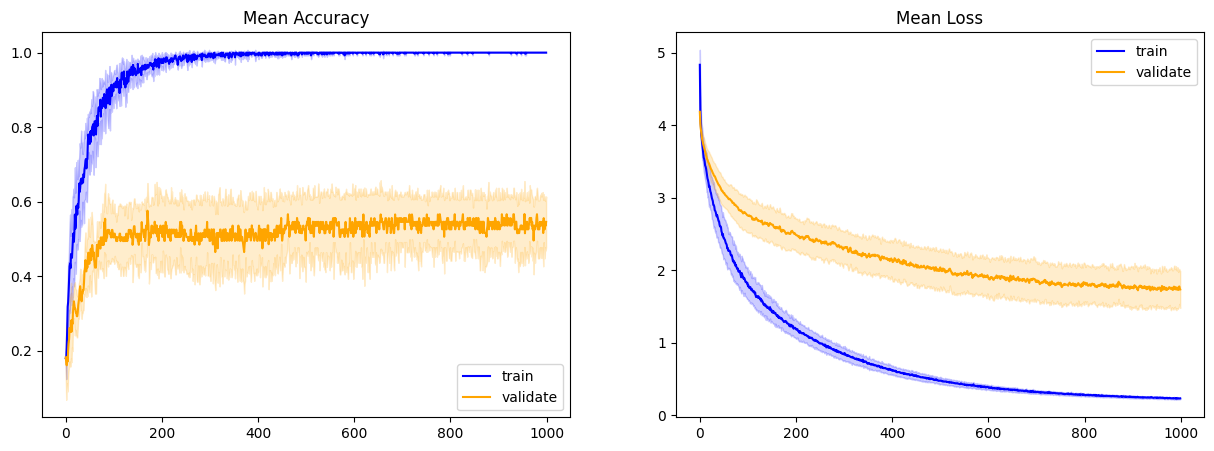

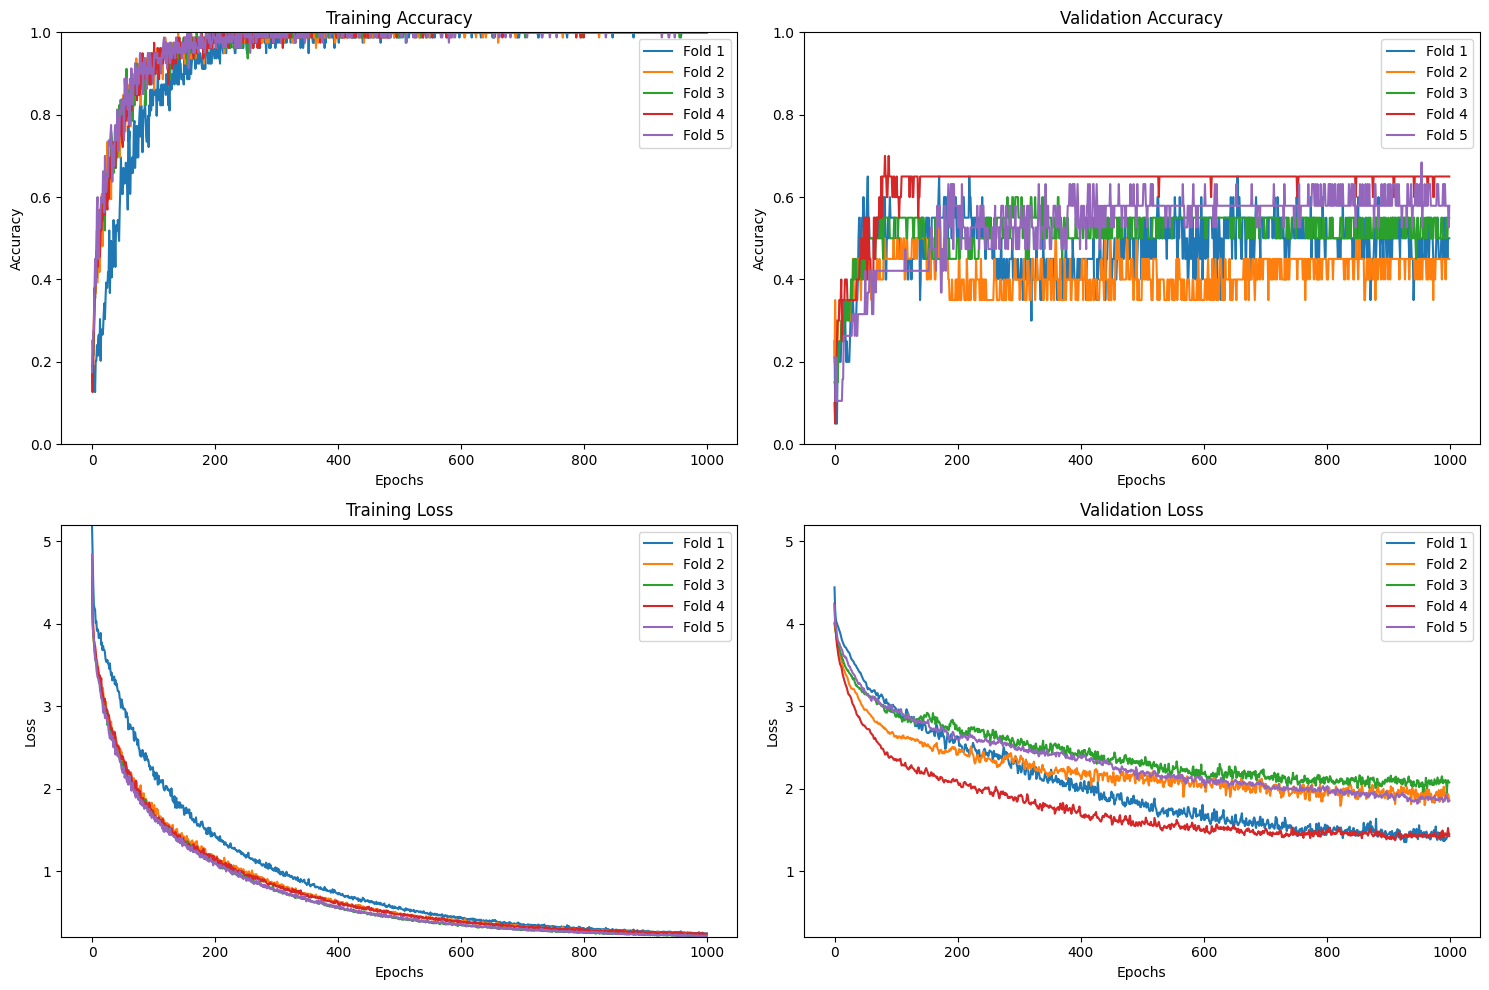

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
predicted classes:       [1 0 4 1 0 0 3 1 2 4 0 4 4 1 3 0 4 0 3]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


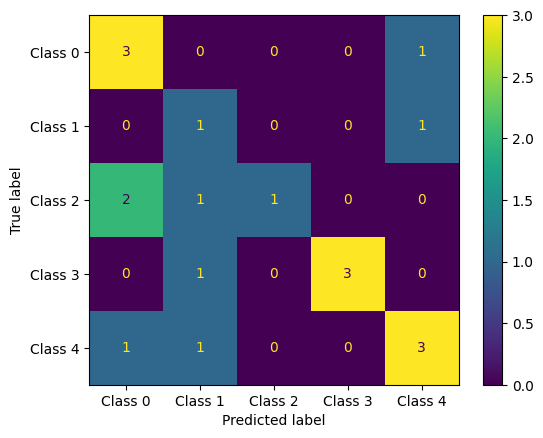

In [16]:
mean_acc_DNN_5_val, sd_acc_DNN_5_val = crossvalidate(df_train_val, model5, predictors,'pond_5', kf, epochs = 1000)

### model testing
After model tuning on training / validation set its time we test it
we will start by extracting predicted classes from our predictions

In [17]:
X_train = df_train_val[predictors].values
y_train = keras.utils.to_categorical(df_train_val['pond_5'].values)
X_test = df_test[predictors].values
y_test = keras.utils.to_categorical(df_test['pond_5'].values)

In [18]:
es = EarlyStopping(monitor='val_loss', patience=30)

In [19]:
reset_weights(model5)

In [20]:
history1=model5.fit(X_train, y_train, epochs = 1000, verbose = 0, shuffle = True, validation_data=(X_test, y_test), callbacks = [es])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7600 - loss: 1.1499
[1.1499097347259521, 0.7599999904632568]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Predicted values: [1 2 2 1 3 1 0 1 2 2 1 3 2 0 4 1 3 0 2 2 0 1 1 3 2]
True values: [3 0 2 1 3 1 0 1 2 2 4 3 4 0 4 1 3 0 2 4 0 1 4 3 2]
Test accuracy: 0.7599999904632568


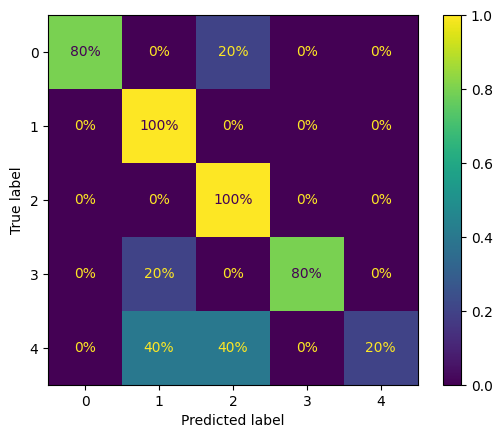

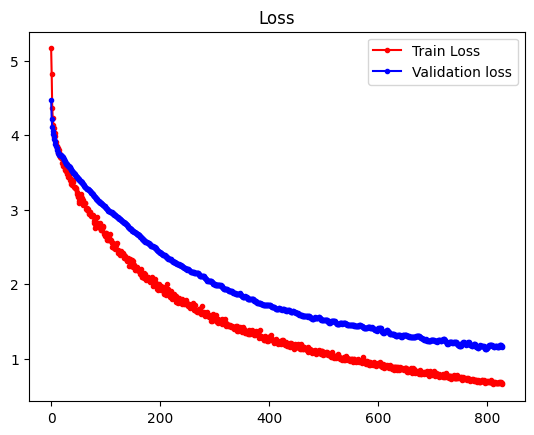

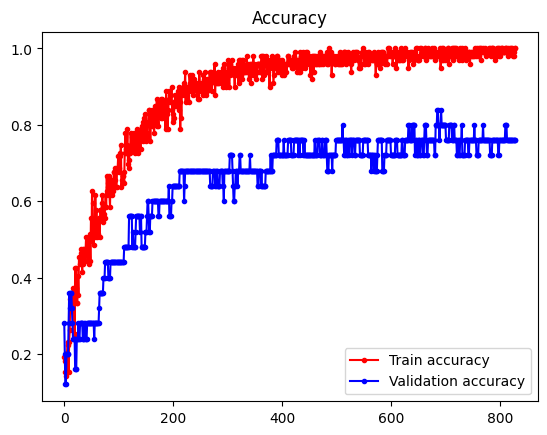

In [21]:
acc_DNN_5_test = evaluate_model(model5, history1, X_test, y_test, acc_name = "Accuracy", loss_name = "Loss")

On those plots we can see that the results on test dataset are pretty bad which is interesting as crossvalidataion resuls seems to be quite better. Nevertheless test set accuracy barely excides random values. 

Explanation of pond coding

| number | setup | pond numbers | water supplementation | feed suplementation |
|---|---|---|---|---|
|0|control | 8,14,18,24,29|NO|NO|
|1|set 1 | 12,16,19,23,26|Em farma|NO|
|2|set 2 | 10,21,28,30,32|Em farma|EM|
|3|set 3 | 9,13,17,20,27|EM|NO|
|4|set 4 | 11,15,22,25,31|EM|EM|

We will now perform class reduction based on biological asumptions, and we wil divide our set into 3 classes (controll, with feed supplementation, without feed supplementation)

## 3 classes
Here we will divide dataset into 3 classes 
0 - control (no water or feed suplementation)
1 - no feed suplementation 
2 - feed suplementation

In [22]:
y_train = keras.utils.to_categorical(df_train_val['pond_3'].values)
y_test = keras.utils.to_categorical(df_test['pond_3'].values)

In [23]:
df = df.copy()

### model building and compiling


In [24]:
model3 = keras.Sequential([
    Dense(128, input_shape=(len(predictors),), activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    Dropout(rate=0.25),
    Dense(64, activation ='relu',kernel_regularizer=keras.regularizers.l2(0.01)),
    Dense(16, activation ='relu',kernel_regularizer=keras.regularizers.l2(0.01)),
    Dense(3, activation ='softmax')


])


model3.summary()

loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.001)
model3.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,603 (100.01 KB)

 Trainable params: 25,603 (100.01 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation


Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.7500 - loss: 0.8631
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
predicted classes:       [1 1 2 2 2 0 0 2 1 1 1 2 2 2 1 2 2 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 360.139, sd confidence score: 869.1134
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5000 - loss: 1.9331
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [1 2 2 2 2 2 2 2 1 2 2 1 2 2 2 2 1 0 2 0]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 1264.8635, sd confidence score: 2263.8347
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8000 - loss: 1.2072
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
predicted classes:       [1 1 1 2 0 1 2 1 1 2 1 1 2 2 2 1 1 1 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 32518.4034, sd confidence scor

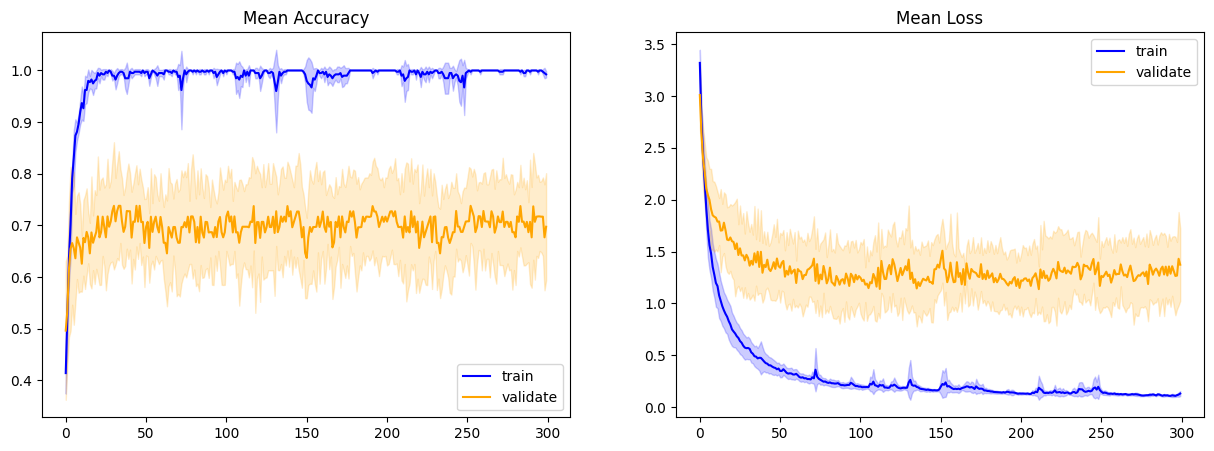

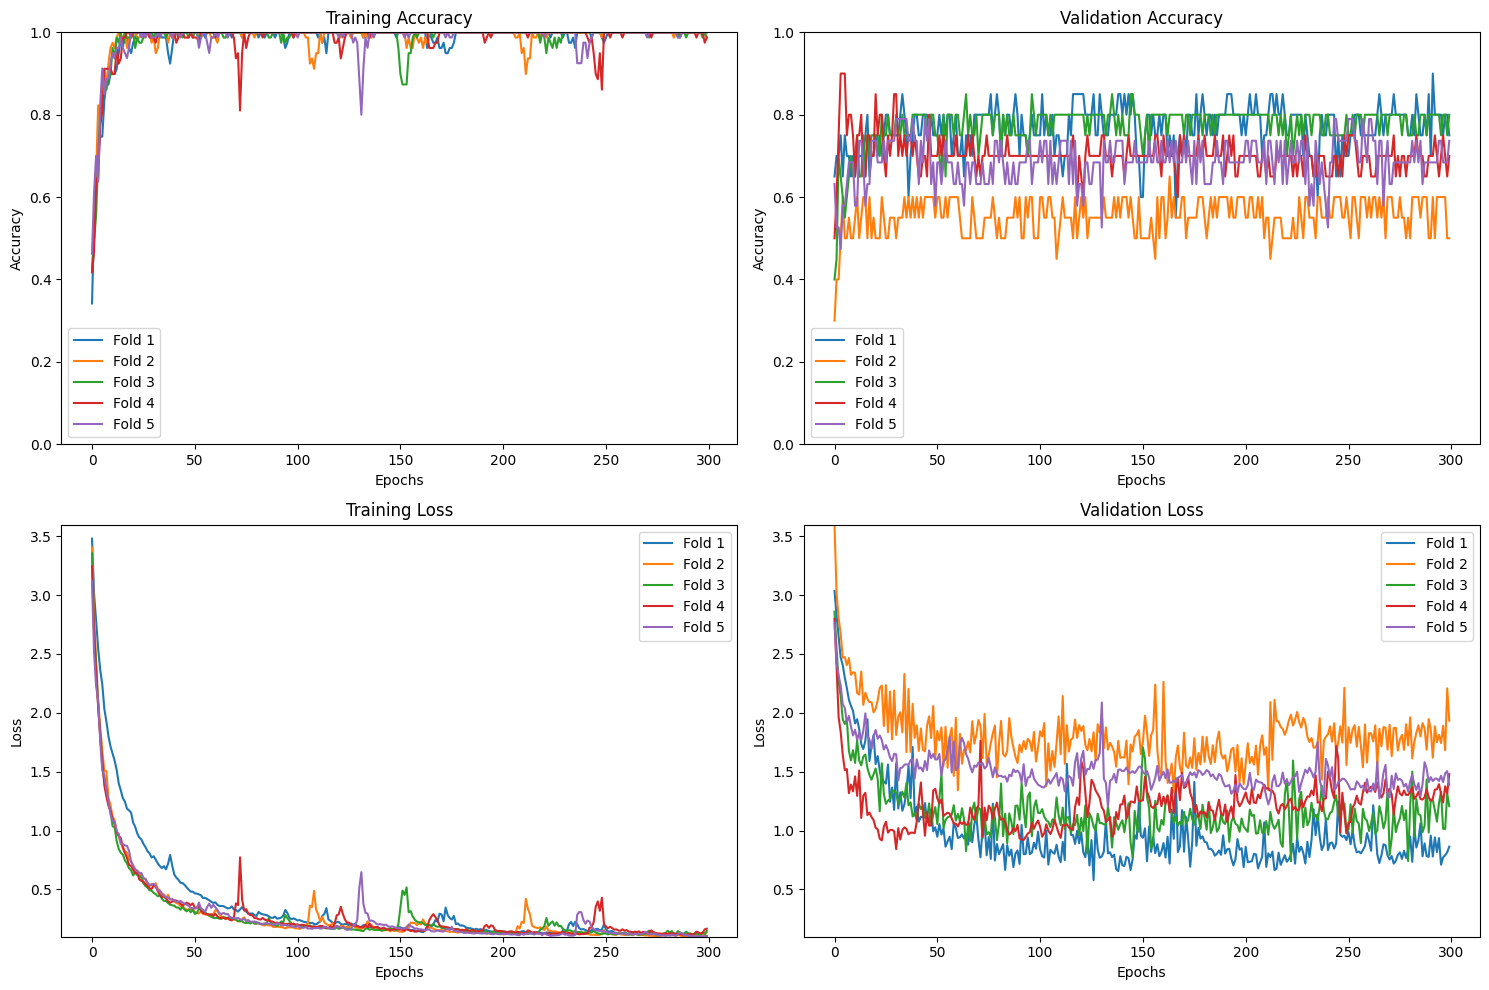

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
predicted classes:       [2 0 2 2 0 0 1 1 2 0 0 2 2 1 2 0 2 0 1]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


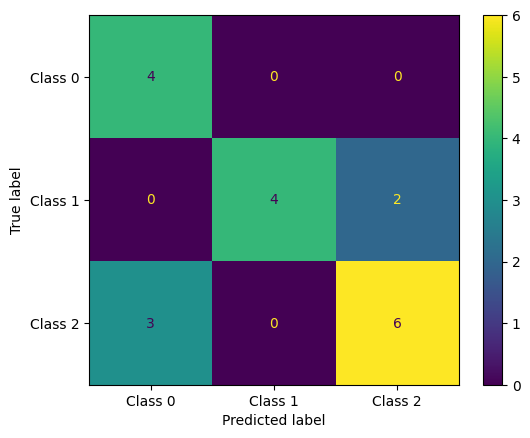

In [25]:
mean_acc_DNN_3_val, sd_acc_DNN_3_val = crossvalidate(df_train_val, model3, predictors, 'pond_3', kf)

In [26]:
reset_weights(model3)
es = EarlyStopping(monitor='val_loss', patience=100)
history3=model3.fit(X_train, y_train, epochs = 750, verbose = 0, shuffle = True, validation_data=(X_test, y_test), callbacks = [es])


### model testing

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8400 - loss: 0.4675
[0.4674570560455322, 0.8399999737739563]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Predicted values: [1 2 2 1 1 1 0 1 2 2 1 1 2 0 2 0 1 0 2 2 0 1 1 1 2]
True values: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
Test accuracy: 0.8399999737739563


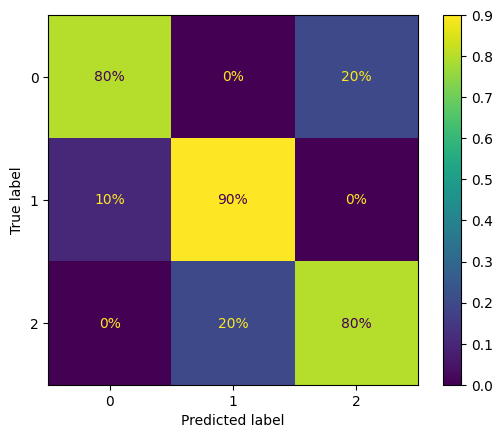

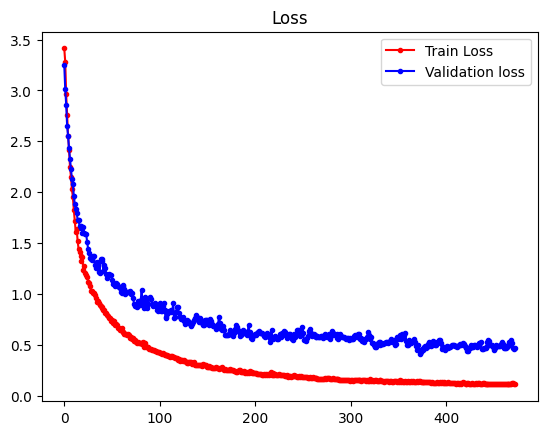

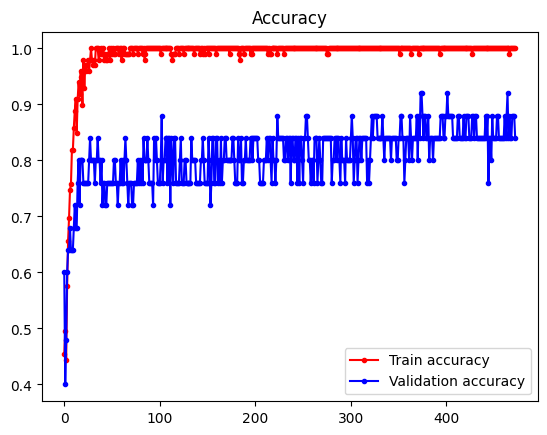

In [27]:
acc_DNN_3_test = evaluate_model(history = history3, model = model3, X_test = X_test, y_test = y_test, acc_name = "Accuracy", loss_name = "Loss")

To remind ourselves what classes look like 

| number | class | pond numbers | feed suplementation |
|---|---|---|---|
|0|control(0) | 8,14,18,24,29|NO|
|1|1|12,16,19,23,26,9,13,17,20,27|NO|
|2|2| 10,21,28,30,32,11,15,22,25,31|EM|


As we can see this did help a bit, accuracy rised a little (we have to account for smaller number of classes) to around 0.7. Looking at confusion matrix the results for class 2 seems to be alright the problem is with model confusing clas 0 and 1, although it is understandable why model is confusing control with 1 class based on conclusions we draw before that feed suplementation has much more impact it is weird that model is misstaking 0 class as 2 class. We might try binary classification approach based only on feed suplementation without control group. 

## 2 classes
As we mentioned later here we will focus only on 2 classes 
- 0 - no feed classification 
- 1 - feed suplementation 

### model building and compiling

In [28]:
model2 = keras.Sequential([
    Dense(128, input_shape=(len(predictors),), activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    Dropout(rate=0.25),
    Dense(64, activation ='relu',kernel_regularizer=keras.regularizers.l2(0.01)),
    Dense(16, activation ='relu',kernel_regularizer=keras.regularizers.l2(0.01)),
    Dense(2, activation ='softmax')
])


model2.summary()

loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.0001)
model2.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,586 (99.95 KB)

 Trainable params: 25,586 (99.95 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation


Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.8000 - loss: 0.3800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
predicted classes:       [0 0 1 0 1 0 0 0 0 0 0 0 1 1 0 1 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 809.7781, sd confidence score: 1466.3226
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7500 - loss: 0.8178
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
predicted classes:       [0 1 1 1 1 0 1 1 0 0 1 0 1 1 1 1 0 0 1 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 450.4428, sd confidence score: 706.8471
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8500 - loss: 0.4961
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
predicted classes:       [0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 0 0 0 1 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 3025.8577, sd confidence score

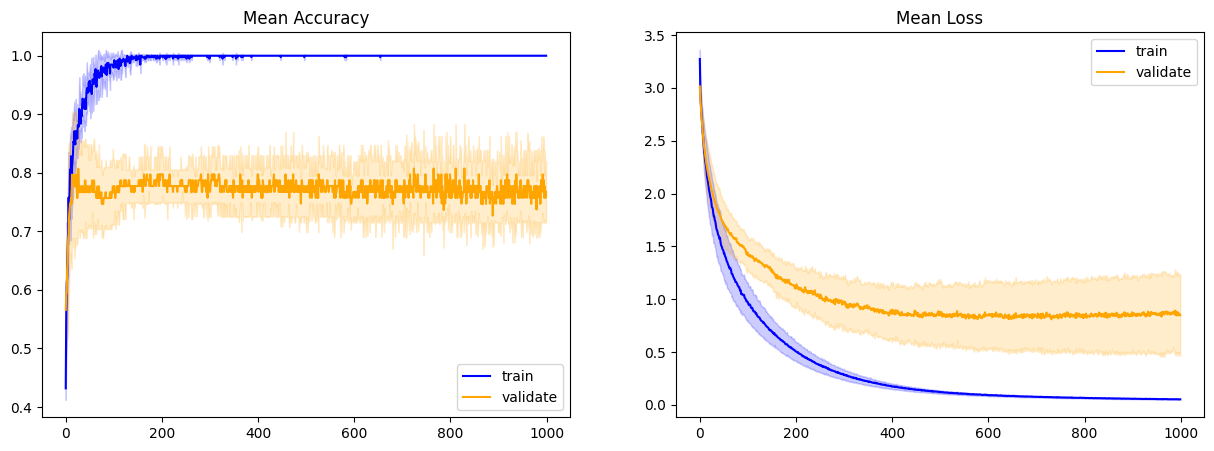

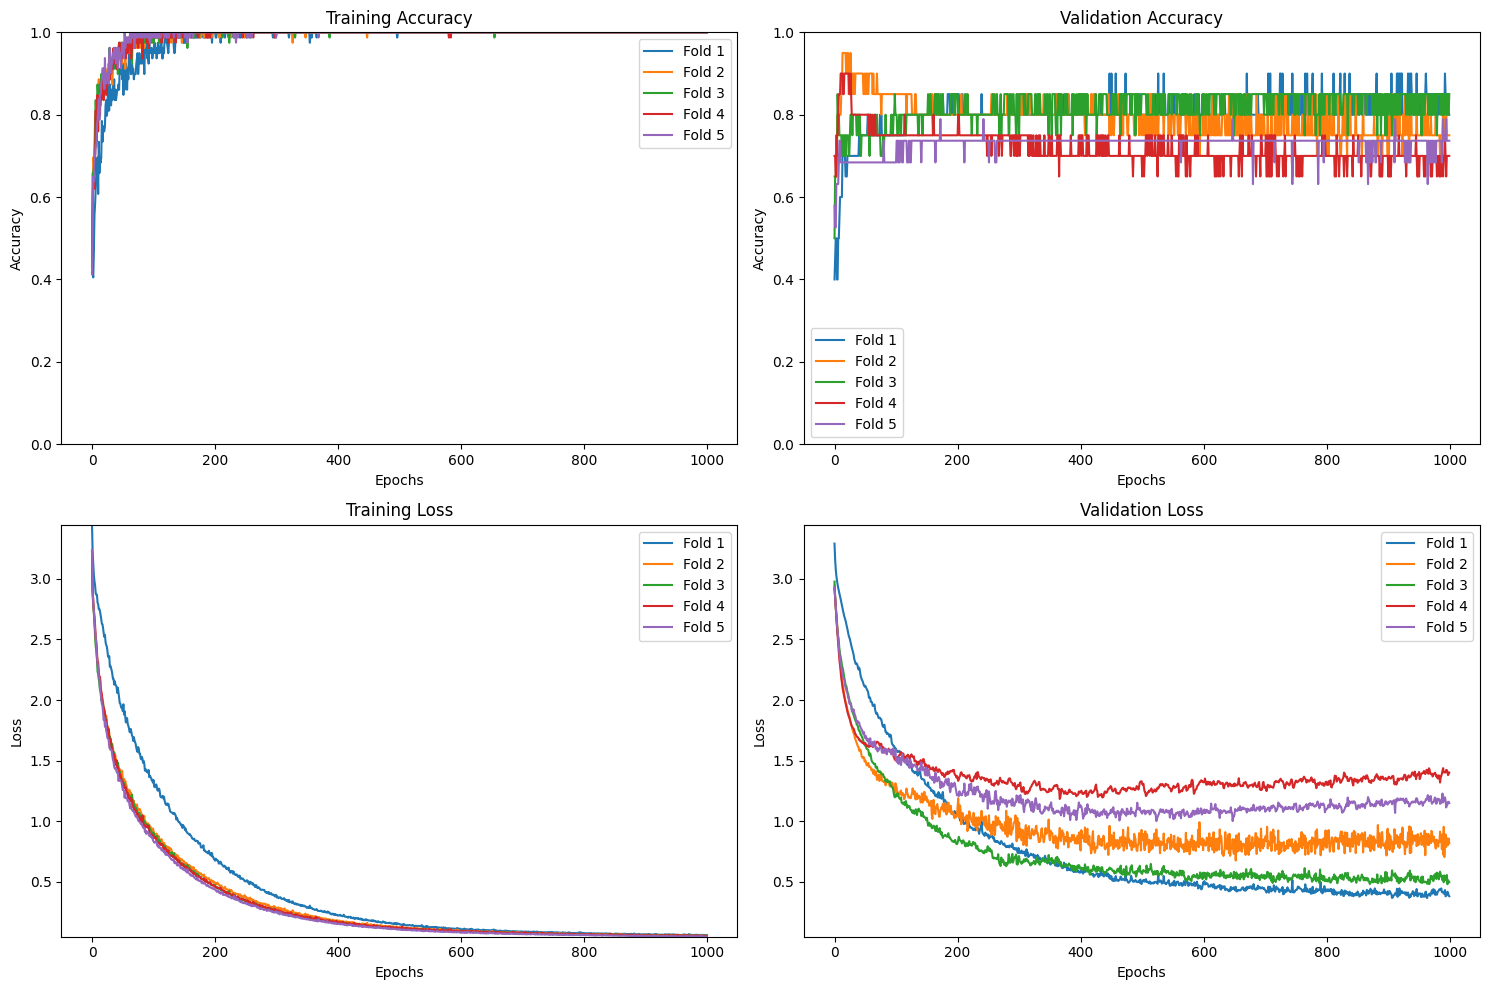

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [0 0 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 0 0]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


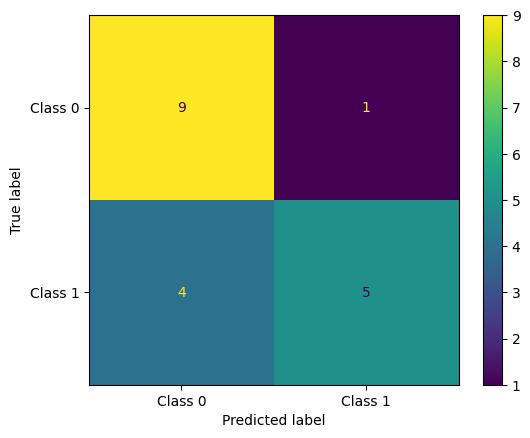

In [29]:
mean_acc_DNN_2_val, sd_acc_DNN_2_val = crossvalidate(df_train_val, model2, predictors, 'pond_2', kf, epochs=1000)

In [30]:
y_train = keras.utils.to_categorical(df_train_val['pond_2'].values)
y_test = keras.utils.to_categorical(df_test['pond_2'].values)

In [31]:
reset_weights(model2)
history2=model2.fit(X_train, y_train, epochs = 750, verbose = 0, shuffle = True, validation_data=(X_test, y_test), callbacks = [es])

### model testing

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8000 - loss: 1.6789
[1.678924560546875, 0.800000011920929]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Predicted values: [0 0 1 0 0 1 0 0 1 1 0 1 1 0 1 0 0 0 0 1 0 0 0 0 1]
True values: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
Test accuracy: 0.800000011920929


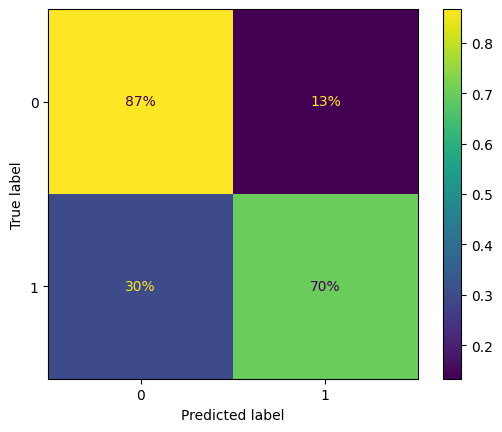

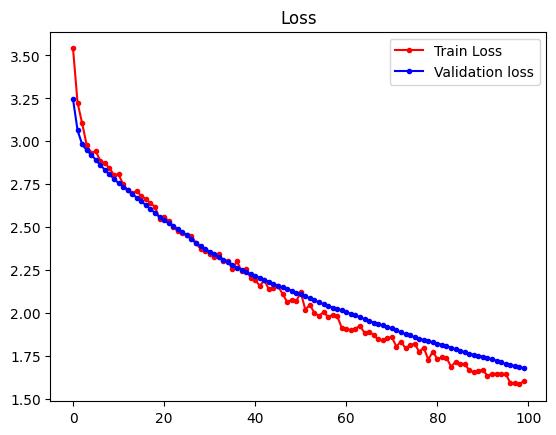

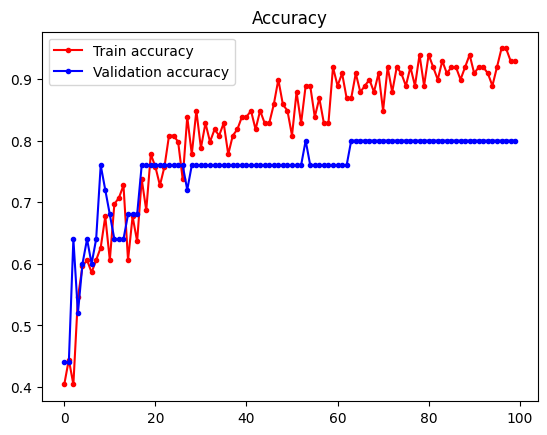

In [32]:
acc_DNN_2_test = evaluate_model(history = history2, model = model2, X_test = X_test, y_test = y_test, acc_name = "Accuracy", loss_name = "Loss")

To remind ourselves what the current classes look like 

| number | class | pond numbers | feed suplementation |
|---|---|---|---|
|0|0|8,14,18,24,29,12,16,19,23,26,9,13,17,20,27|NO|
|1|1| 10,21,28,30,32,11,15,22,25,31|YES|

We can see quite good accuracy of 0.9 although we reducend number of classes this combined with probably more accurate biological classes made results quite good. We will now perform comparison with XGBoost classification tool to get the alternative results. 

# Shallow model
The idea is due to small sample size to try out very simple shallow model 

## 5 classes

In [33]:
kf = KFold(n_splits=5, shuffle=True, random_state=111)

In [34]:
model5_s = keras.Sequential([
    Dense(128, input_shape=(len(predictors),), activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    Dropout(rate=0.25),
    Dense(5, activation='softmax')
])
model5_s.summary()
loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.0001)
model5_s.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,901 (66.02 KB)

 Trainable params: 16,901 (66.02 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation


Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.7000 - loss: 0.9084
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
predicted classes:       [1 3 4 0 2 0 0 1 3 1 1 4 2 4 0 2 4 1 2 4]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 32.1919, sd confidence score: 76.6655
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5500 - loss: 1.8377
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
predicted classes:       [3 4 1 4 4 2 4 2 3 4 1 3 4 4 4 2 3 1 2 0]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 796.7366, sd confidence score: 3062.799
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5500 - loss: 1.9197
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [4 3 3 2 0 4 4 3 1 4 1 3 4 4 2 3 3 1 4 1]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 1898.3132, sd confidence score: 7

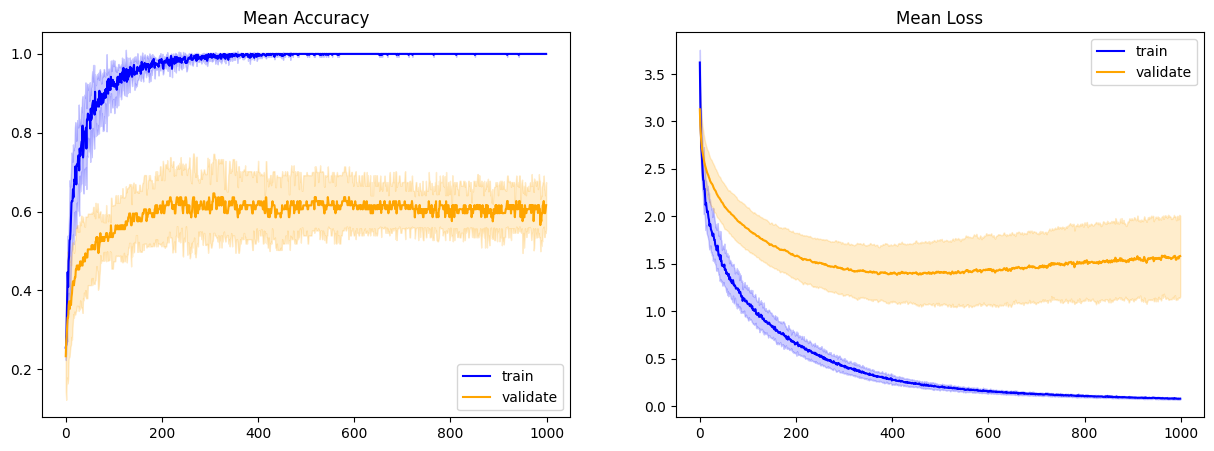

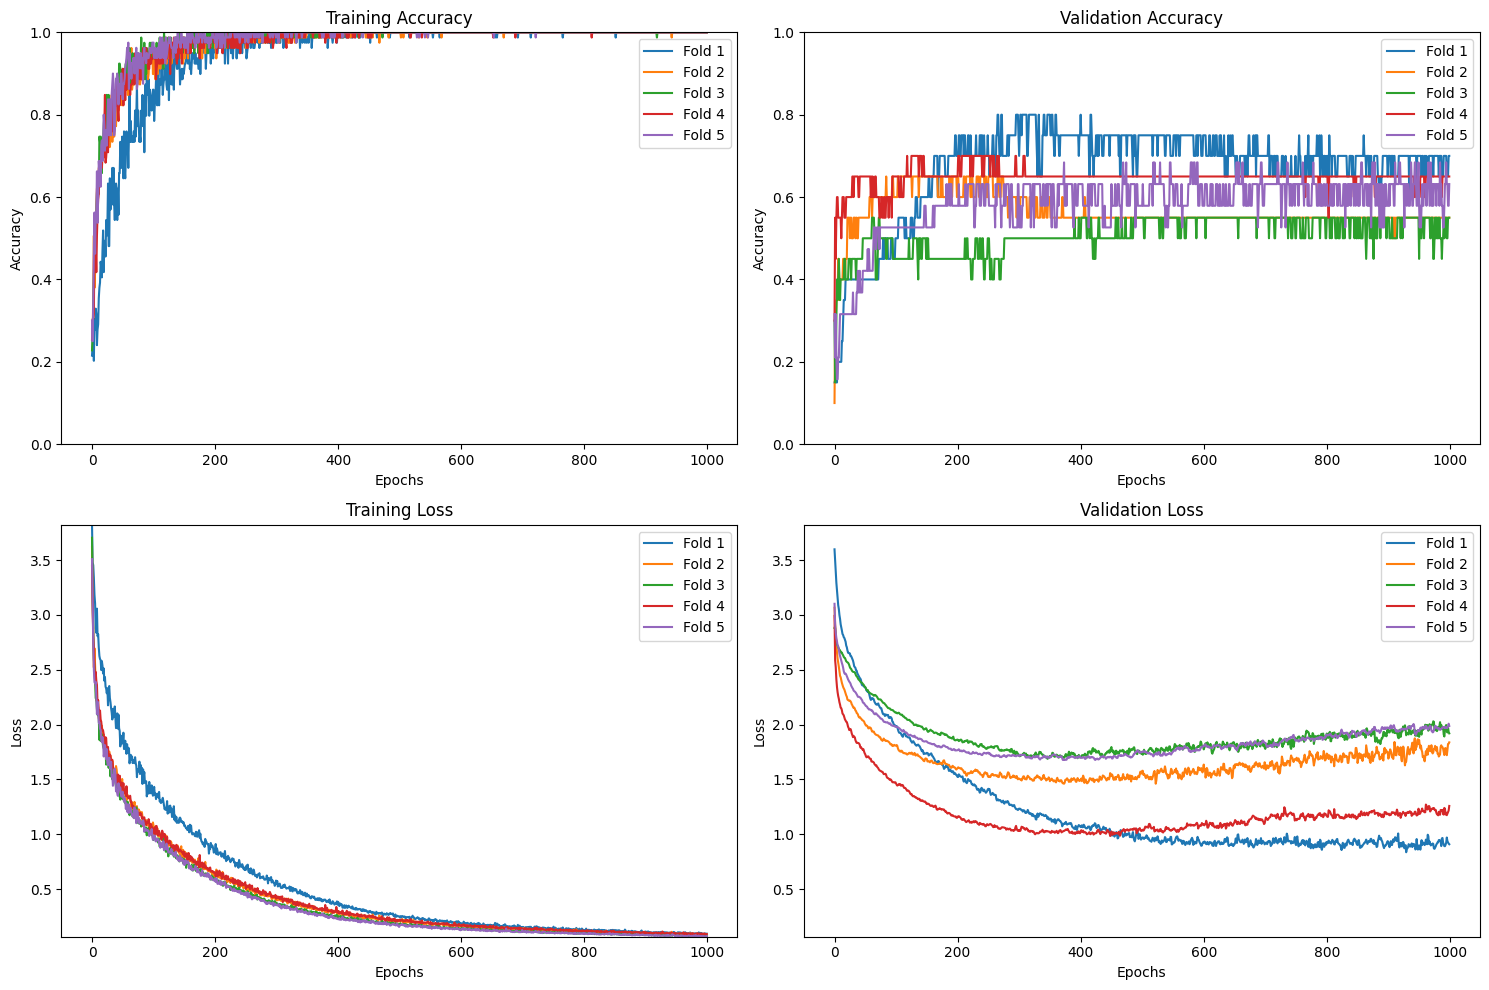

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
predicted classes:       [1 0 4 2 0 0 3 1 2 4 0 4 4 1 3 0 4 0 3]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


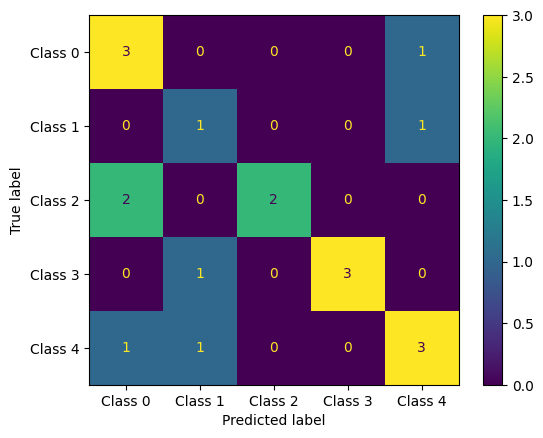

In [35]:
mean_acc_SNN_5_val, sd_acc_SNN_5_val = crossvalidate(df_train_val, model5_s, predictors,'pond_5', kf, epochs = 1000)

### model testing
After model tuning on training / validation set its time we test it
we will start by extracting predicted classes from our predictions

In [36]:
X_train = df_train_val[predictors].values
y_train = keras.utils.to_categorical(df_train_val['pond_5'].values)
X_test = df_test[predictors].values
y_test = keras.utils.to_categorical(df_test['pond_5'].values)

In [37]:
es = EarlyStopping(monitor='val_loss', patience=30)

In [38]:
reset_weights(model5_s)

In [39]:
history1=model5_s.fit(X_train, y_train, epochs = 1000, verbose = 0, shuffle = True, validation_data=(X_test, y_test), callbacks = [es])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8000 - loss: 0.7122
[0.7122325301170349, 0.800000011920929]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Predicted values: [1 2 2 1 3 1 0 1 2 4 4 3 4 0 4 1 3 0 2 2 0 1 1 3 2]
True values: [3 0 2 1 3 1 0 1 2 2 4 3 4 0 4 1 3 0 2 4 0 1 4 3 2]
Test accuracy: 0.800000011920929


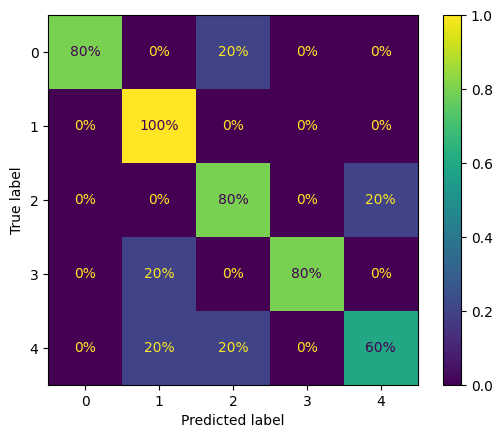

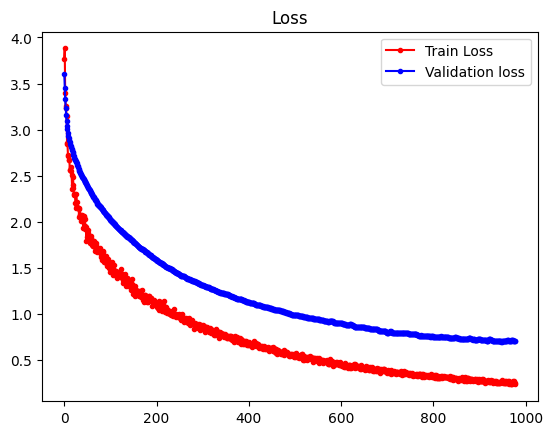

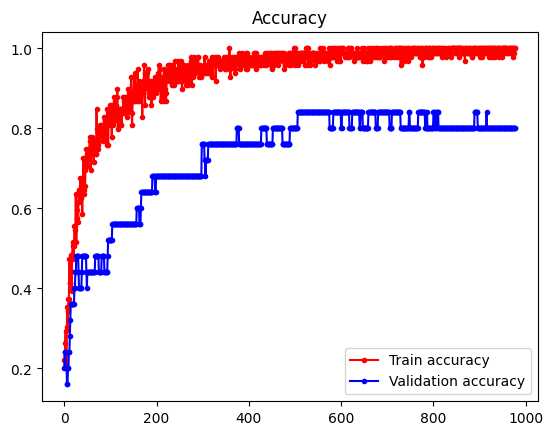

In [40]:
acc_SNN_5_test = evaluate_model(model5_s, history1, X_test, y_test, acc_name = "Accuracy", loss_name = "Loss")

On those plots we can see that the results on test dataset are pretty bad which is interesting as crossvalidataion resuls seems to be quite better. Nevertheless test set accuracy barely excides random values. 

Explanation of pond coding

| number | setup | pond numbers | water supplementation | feed suplementation |
|---|---|---|---|---|
|0|control | 8,14,18,24,29|NO|NO|
|1|set 1 | 12,16,19,23,26|Em farma|NO|
|2|set 2 | 10,21,28,30,32|Em farma|EM|
|3|set 3 | 9,13,17,20,27|EM|NO|
|4|set 4 | 11,15,22,25,31|EM|EM|

We will now perform class reduction based on biological asumptions, and we wil divide our set into 3 classes (controll, with feed supplementation, without feed supplementation)

## 3 classes
Here we will divide dataset into 3 classes 
0 - control (no water or feed suplementation)
1 - no feed suplementation 
2 - feed suplementation

In [41]:
y_train = keras.utils.to_categorical(df_train_val['pond_3'].values)
y_test = keras.utils.to_categorical(df_test['pond_3'].values)

In [42]:
df = df.copy()

### model building and compiling


In [43]:

model3_s = keras.Sequential([
    keras.layers.Dense(128, input_shape=(len(predictors),), activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    keras.layers.Dropout(rate=0.25),
    keras.layers.Dense(3, activation ='softmax')

])
model3_s.summary()

loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.001)
model3_s.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 128)            │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,643 (65.01 KB)

 Trainable params: 16,643 (65.01 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation


Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.7500 - loss: 0.7347
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
predicted classes:       [1 1 2 2 2 1 1 1 1 1 1 2 2 2 1 2 1 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 637.8558, sd confidence score: 2173.0233
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6000 - loss: 1.7811
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [1 2 2 2 2 1 2 2 1 1 2 1 2 2 2 2 1 1 2 1]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 9998.311, sd confidence score: 39854.4405
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7500 - loss: 1.2389
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [1 1 1 2 0 1 2 1 1 2 1 1 2 2 2 1 2 1 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 1437537178.7306, sd confiden

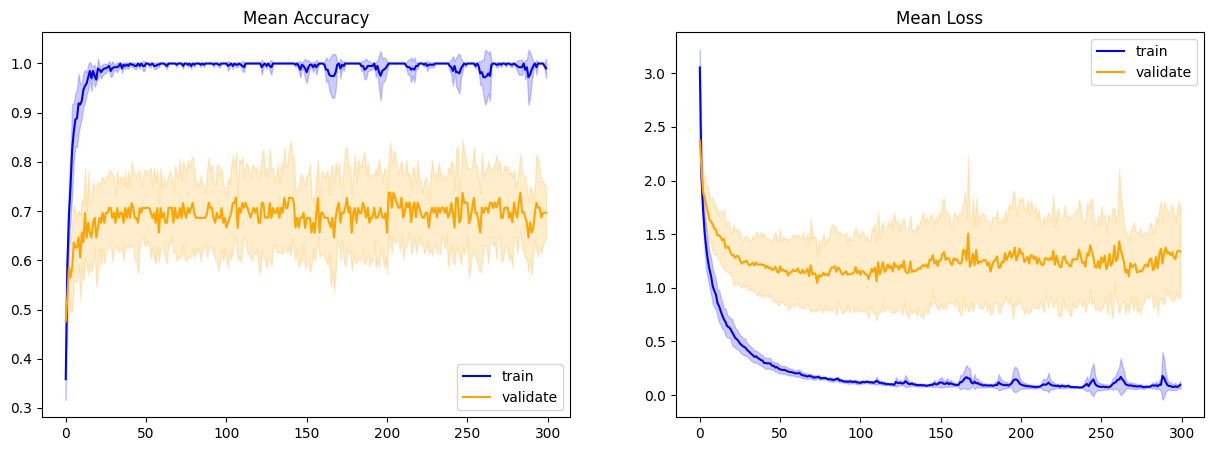

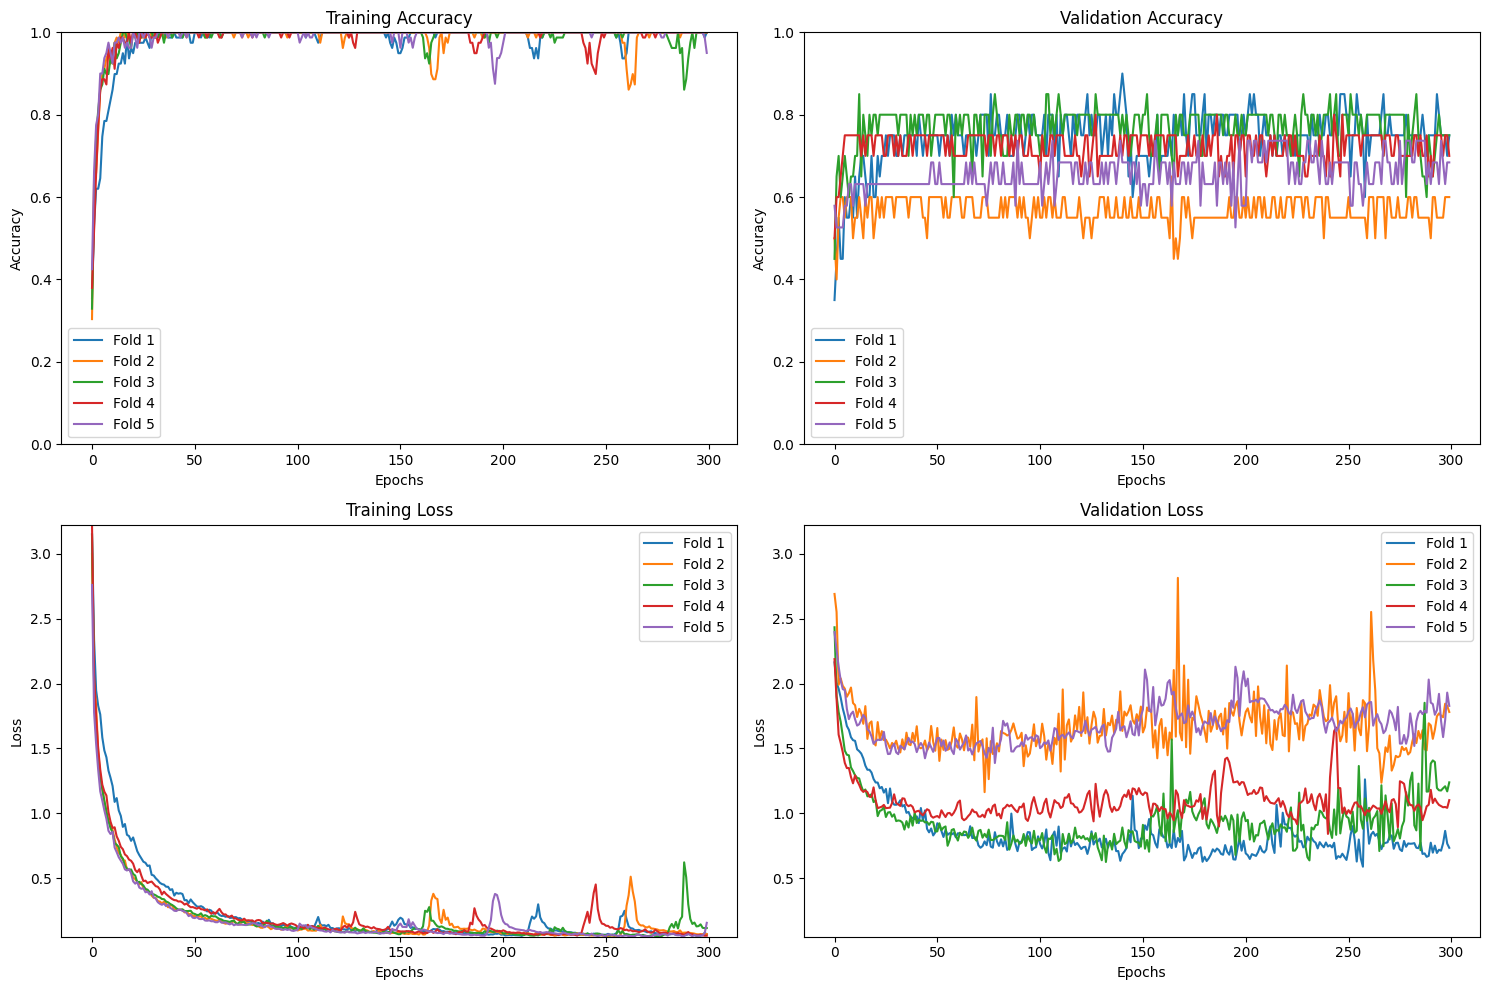

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [2 0 2 2 0 0 1 1 2 2 0 2 2 1 2 0 2 0 1]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


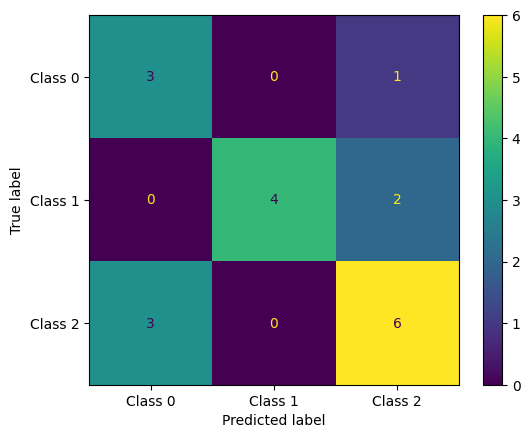

In [44]:
mean_acc_SNN_3_val, sd_acc_SNN_3_val = crossvalidate(df_train_val, model3_s, predictors, 'pond_3', kf)

In [45]:
reset_weights(model3_s)
es = EarlyStopping(monitor='val_loss', patience=100)
history3=model3_s.fit(X_train, y_train, epochs = 750, verbose = 0, shuffle = True, validation_data=(X_test, y_test), callbacks = [es])


### model testing

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8800 - loss: 0.3309
[0.33089718222618103, 0.8799999952316284]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Predicted values: [1 2 2 1 1 1 0 1 2 2 2 2 2 0 2 1 1 0 2 2 0 1 1 1 2]
True values: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
Test accuracy: 0.8799999952316284


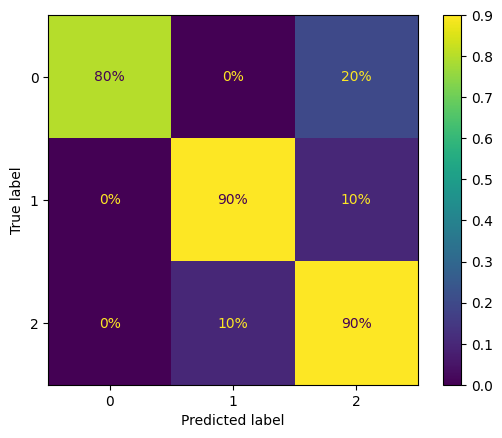

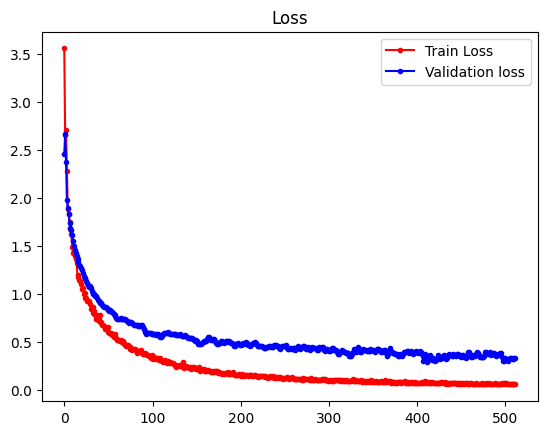

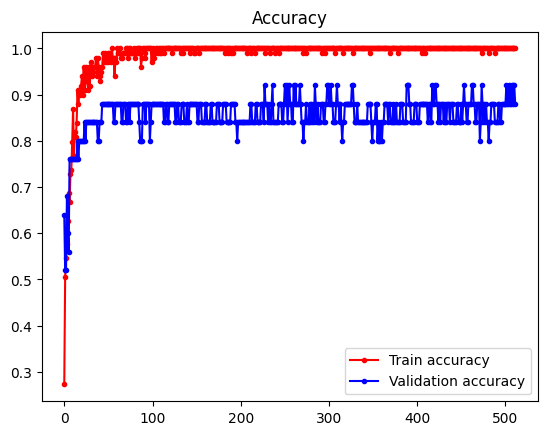

In [46]:
acc_SNN_3_test = evaluate_model(history = history3, model = model3_s, X_test = X_test, y_test = y_test, acc_name = "Accuracy", loss_name = "Loss")

To remind ourselves what classes look like 

| number | class | pond numbers | feed suplementation |
|---|---|---|---|
|0|control(0) | 8,14,18,24,29|NO|
|1|1|12,16,19,23,26,9,13,17,20,27|NO|
|2|2| 10,21,28,30,32,11,15,22,25,31|EM|


As we can see this did help a bit, accuracy rised a little (we have to account for smaller number of classes) to around 0.7. Looking at confusion matrix the results for class 2 seems to be alright the problem is with model confusing clas 0 and 1, although it is understandable why model is confusing control with 1 class based on conclusions we draw before that feed suplementation has much more impact it is weird that model is misstaking 0 class as 2 class. We might try binary classification approach based only on feed suplementation without control group. 

## 2 classes
As we mentioned later here we will focus only on 2 classes 
- 0 - no feed classification 
- 1 - feed suplementation 

### model building and compiling

In [47]:
model2_s = keras.Sequential([
    Dense(128, input_shape=(len(predictors),), activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    Dropout(rate=0.25),
    Dense(2, activation ='softmax')


])

model2_s.summary()

loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.0001)
model2_s.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,514 (64.51 KB)

 Trainable params: 16,514 (64.51 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation


Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.8500 - loss: 0.4028
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
predicted classes:       [0 0 1 1 1 0 0 0 0 0 0 0 1 1 0 1 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 69385.7336, sd confidence score: 272455.0003
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7000 - loss: 0.7679
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [0 1 1 1 1 0 1 1 0 1 1 0 1 1 1 1 0 0 1 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 3851.6597, sd confidence score: 8314.849
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8000 - loss: 0.4984
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
predicted classes:       [0 0 0 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 1 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 3699459.9656, sd confiden

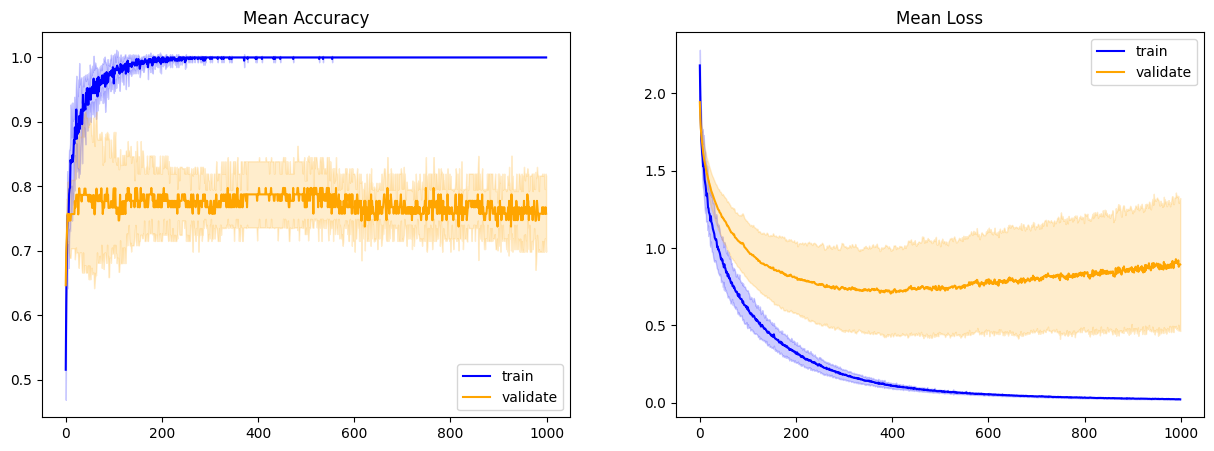

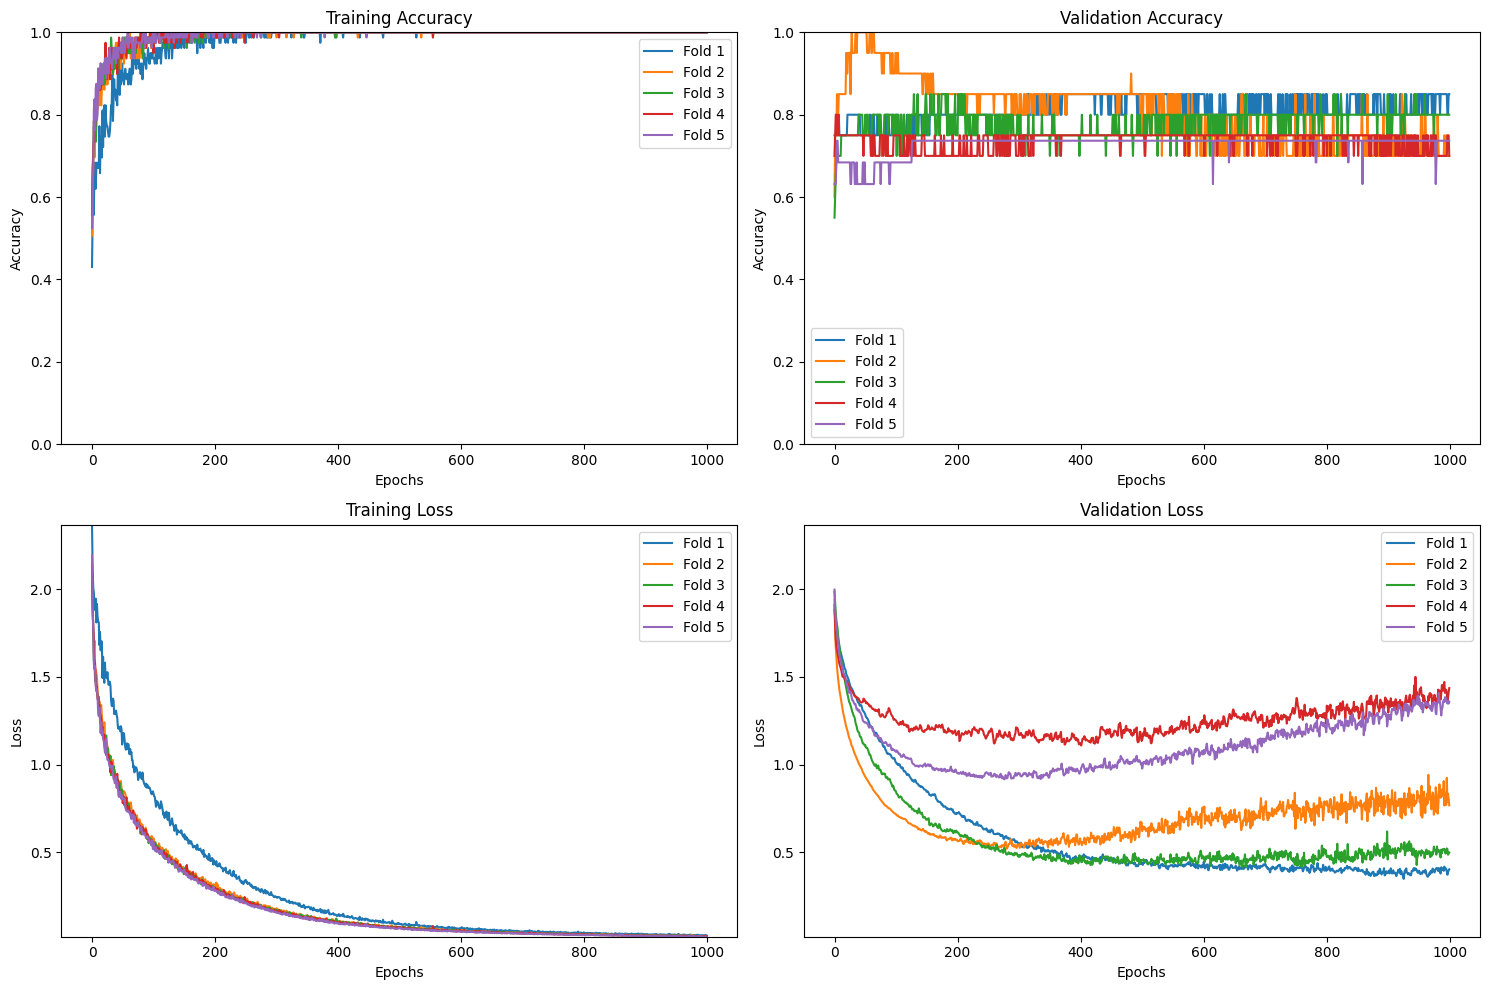

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
predicted classes:       [0 0 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 0 0]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


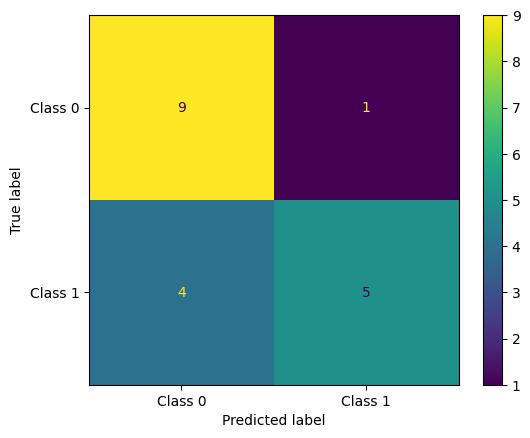

In [48]:
mean_acc_SNN_2_val, sd_acc_SNN_2_val = crossvalidate(df_train_val, model2_s, predictors, 'pond_2', kf, epochs=1000)

In [49]:
y_train = keras.utils.to_categorical(df_train_val['pond_2'].values)
y_test = keras.utils.to_categorical(df_test['pond_2'].values)

In [50]:
reset_weights(model2_s)
history2=model2_s.fit(X_train, y_train, epochs = 750, verbose = 0, shuffle = True, validation_data=(X_test, y_test), callbacks = [es])

### model testing

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8400 - loss: 0.9905
[0.9905470013618469, 0.8399999737739563]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted values: [0 1 1 0 0 0 0 0 1 1 0 1 1 0 1 0 0 0 1 1 0 0 0 0 1]
True values: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
Test accuracy: 0.8399999737739563


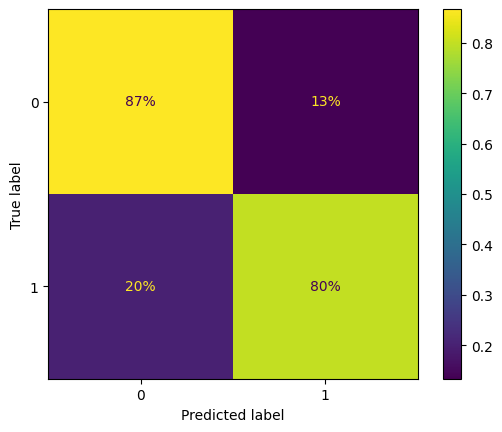

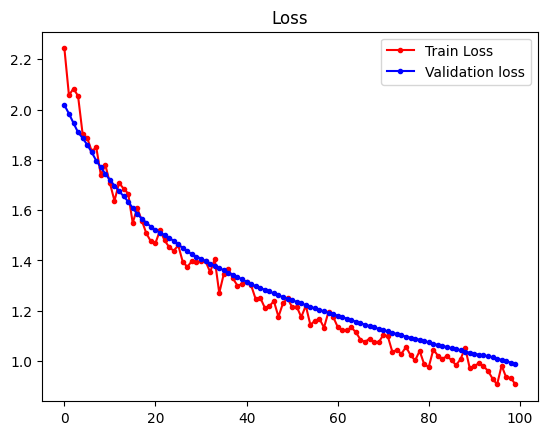

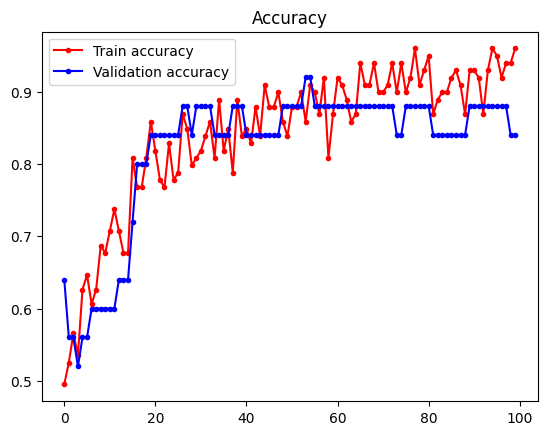

In [51]:
acc_SNN_2_test = evaluate_model(history = history2, model = model2_s, X_test = X_test, y_test = y_test, acc_name = "Accuracy", loss_name = "Loss")

To remind ourselves what the current classes look like 

| number | class | pond numbers | feed suplementation |
|---|---|---|---|
|0|0|8,14,18,24,29,12,16,19,23,26,9,13,17,20,27|NO|
|1|1| 10,21,28,30,32,11,15,22,25,31|YES|

We can see quite good accuracy of 0.9 although we reducend number of classes this combined with probably more accurate biological classes made results quite good. We will now perform comparison with XGBoost classification tool to get the alternative results. 

# XGBoost 

## 5 classes

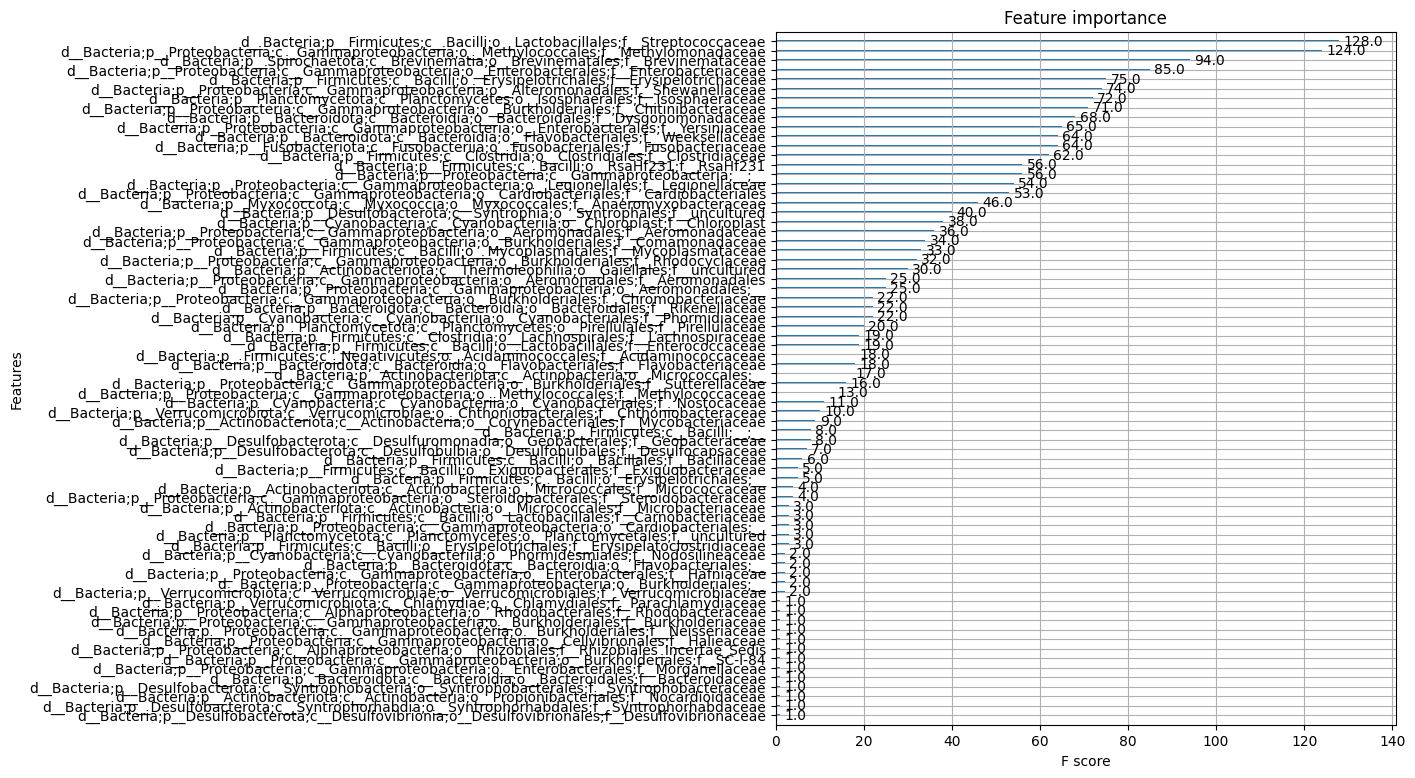

Accuracy: 0.56
true: [3 0 2 1 3 1 0 1 2 2 4 3 4 0 4 1 3 0 2 4 0 1 4 3 2]
predicted: [1. 0. 2. 1. 0. 4. 0. 1. 2. 1. 1. 3. 2. 0. 2. 1. 4. 0. 1. 4. 1. 1. 1. 3.
 2.]


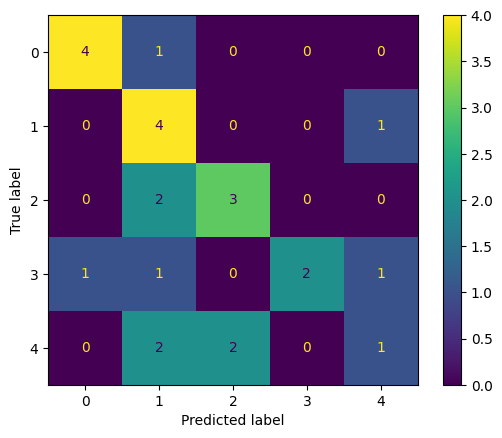

In [52]:
target = "pond_5"
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=predictors.to_list())  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=predictors.to_list())
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, # maximum deepth of the tree, used to controll complexity of the model
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy: {xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

acc_XGB_5_test = xgb_acc
cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

## 3 Classes

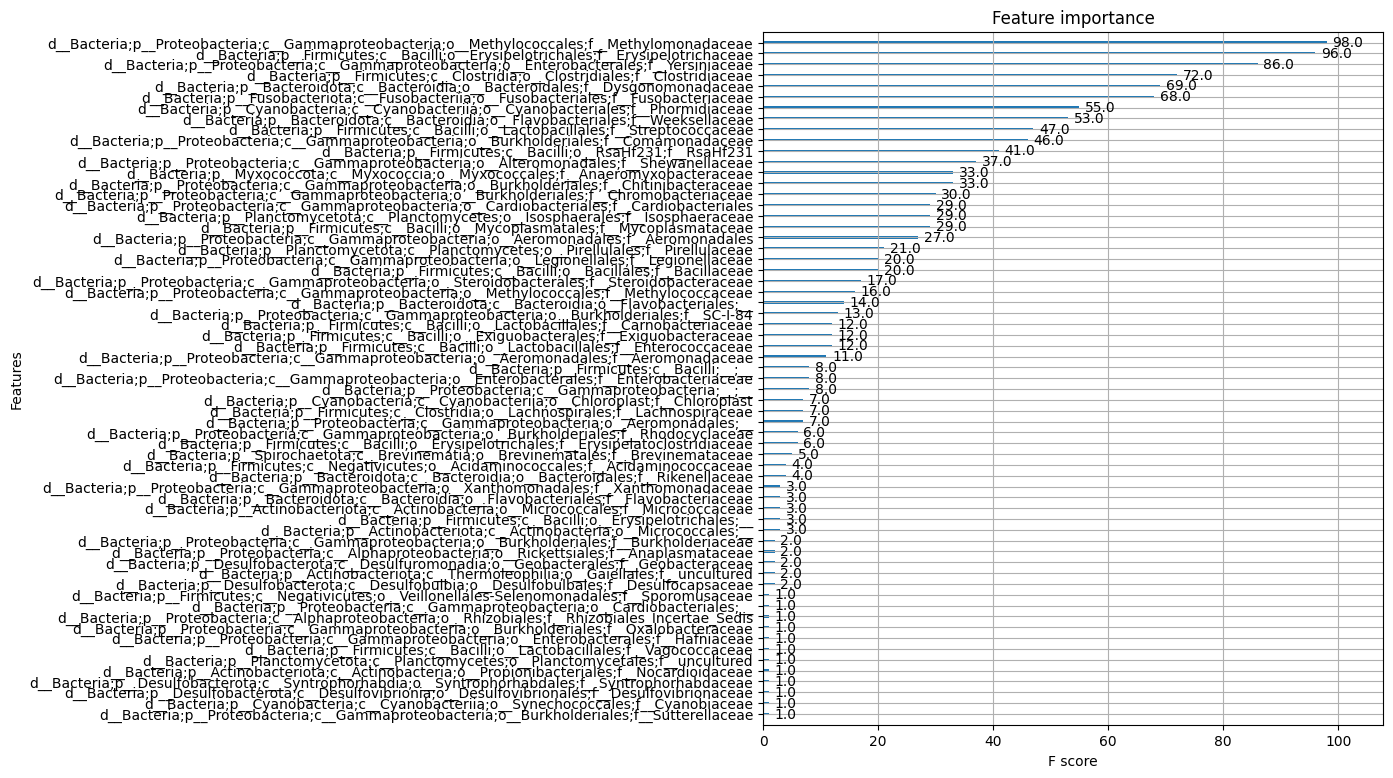

Accuracy0.68
true: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
predicted: [1. 2. 2. 1. 0. 1. 0. 1. 2. 0. 2. 1. 2. 1. 2. 1. 2. 1. 2. 2. 1. 1. 1. 1.
 2.]


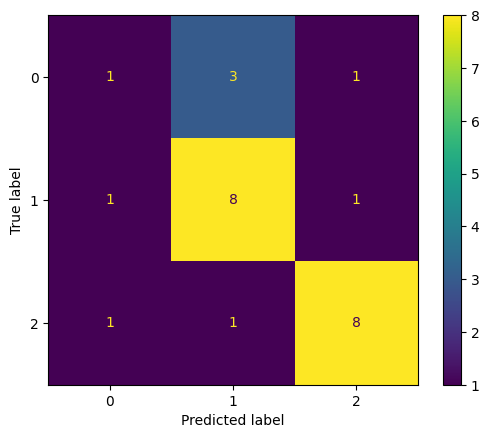

In [53]:
target = "pond_3"
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=predictors.to_list())  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=predictors.to_list())
params = {
    'objective': 'multi:softmax',
    'num_class': 3,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)

fig, ax = plt.subplots(figsize=(8, 9))  
xgb.plot_importance(x2, ax=ax)
plt.show()
print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")
acc_XGB_3_test = xgb_acc
cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

## 2 Classes

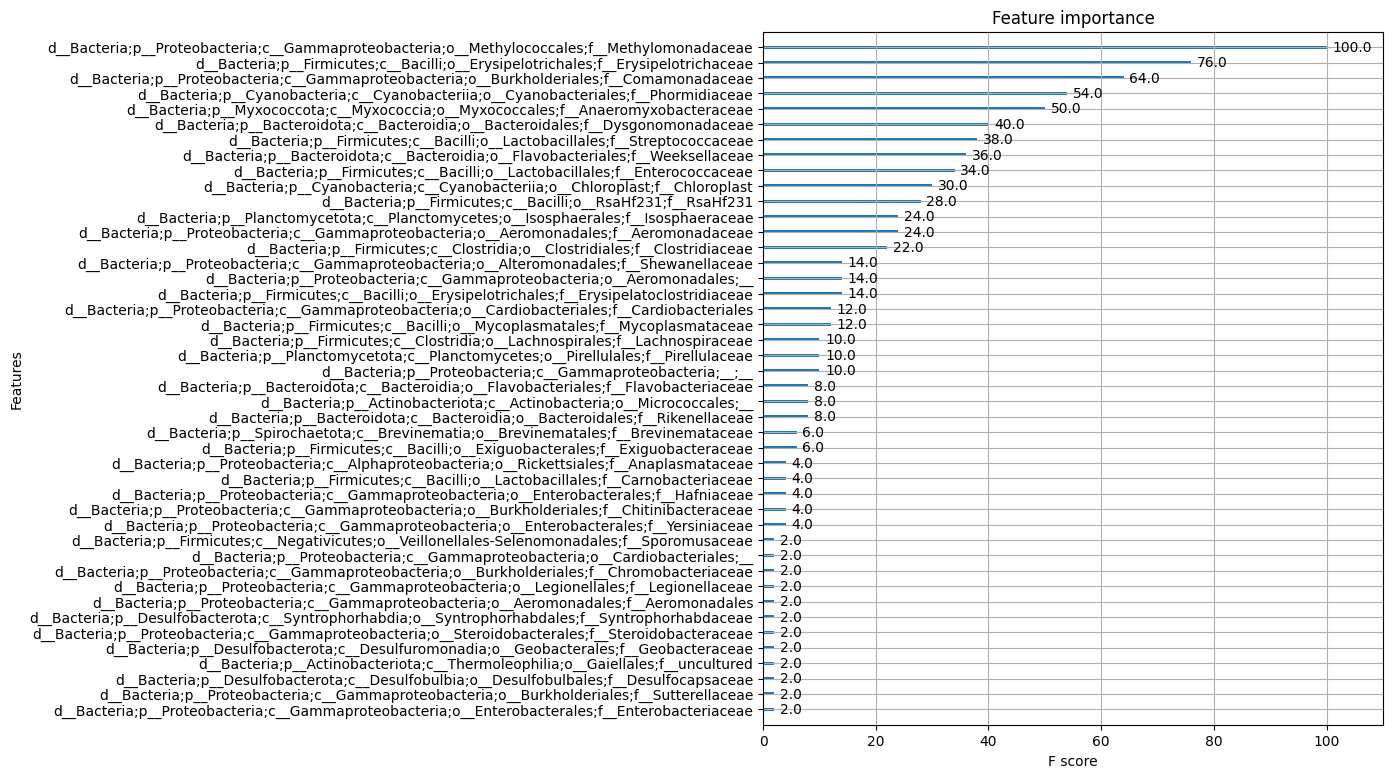

Accuracy0.84
true: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
predicted: [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 1. 0. 0. 0. 0.
 1.]


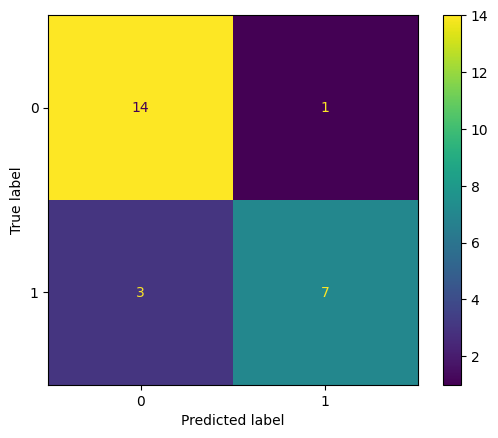

In [54]:
target = "pond_2"
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=predictors.to_list())  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=predictors.to_list())
params = {
    'objective': 'multi:softmax',
    'num_class': 2,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)

fig, ax = plt.subplots(figsize=(8, 9))  
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")
acc_XGB_2_test = xgb_acc
cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

In [55]:
print("DNN")
print(f"Accuracy class 5: {round(mean_acc_DNN_5_val,2)}, sd: {round(sd_acc_DNN_5_val,2)}, test: {acc_DNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_DNN_3_val,2)}, sd: {round(sd_acc_DNN_3_val,2)}, test: {acc_DNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_DNN_2_val,2)}, sd: {round(sd_acc_DNN_2_val,2)}, test: {acc_DNN_2_test}")
print("SNN")
print(f"Accuracy class 5: {round(mean_acc_SNN_5_val,2)}, sd: {round(sd_acc_SNN_5_val,2)}, test: {acc_SNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_SNN_3_val,2)}, sd: {round(sd_acc_SNN_3_val,2)}, test: {acc_SNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_SNN_2_val,2)}, sd: {round(sd_acc_SNN_2_val,2)}, test: {acc_SNN_2_test}")
print("XGB")
print(f"Accuracy class 5: {acc_XGB_5_test}")
print(f"Accuracy class 3: {acc_XGB_3_test}")
print(f"Accuracy class 2: {acc_XGB_2_test}")


DNN
Accuracy class 5: 0.55, sd: 0.07, test: 0.7599999904632568
Accuracy class 3: 0.7, sd: 0.1, test: 0.8399999737739563
Accuracy class 2: 0.77, sd: 0.05, test: 0.800000011920929
SNN
Accuracy class 5: 0.62, sd: 0.06, test: 0.800000011920929
Accuracy class 3: 0.7, sd: 0.06, test: 0.8799999952316284
Accuracy class 2: 0.76, sd: 0.06, test: 0.8399999737739563
XGB
Accuracy class 5: 0.56
Accuracy class 3: 0.68
Accuracy class 2: 0.84


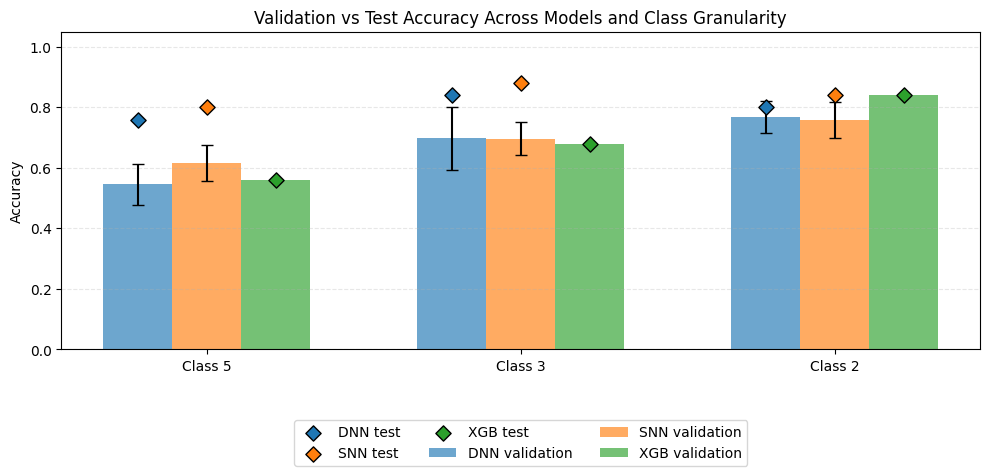

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

accuracy_rows = [
    ("DNN", "Class 5", mean_acc_DNN_5_val, sd_acc_DNN_5_val, acc_DNN_5_test),
    ("DNN", "Class 3", mean_acc_DNN_3_val, sd_acc_DNN_3_val, acc_DNN_3_test),
    ("DNN", "Class 2", mean_acc_DNN_2_val, sd_acc_DNN_2_val, acc_DNN_2_test),
    ("SNN", "Class 5", mean_acc_SNN_5_val, sd_acc_SNN_5_val, acc_SNN_5_test),
    ("SNN", "Class 3", mean_acc_SNN_3_val, sd_acc_SNN_3_val, acc_SNN_3_test),
    ("SNN", "Class 2", mean_acc_SNN_2_val, sd_acc_SNN_2_val, acc_SNN_2_test),
    ("XGB", "Class 5", acc_XGB_5_test, 0.0, acc_XGB_5_test),
    ("XGB", "Class 3", acc_XGB_3_test, 0.0, acc_XGB_3_test),
    ("XGB", "Class 2", acc_XGB_2_test, 0.0, acc_XGB_2_test),
]

accuracy_df = pd.DataFrame(
    accuracy_rows,
    columns=["Model", "Class", "val_mean", "val_sd", "test_acc"],
)

class_labels = ["Class 5", "Class 3", "Class 2"]
model_order = ["DNN", "SNN", "XGB"]
x_positions = np.arange(len(class_labels))
bar_width = 0.22
palette = {"DNN": "#1f77b4", "SNN": "#ff7f0e", "XGB": "#2ca02c"}

fig, ax = plt.subplots(figsize=(10, 5))
for idx, model in enumerate(model_order):
    subset = accuracy_df[accuracy_df["Model"] == model].set_index("Class").loc[class_labels]
    offsets = x_positions + (idx - (len(model_order) - 1) / 2) * bar_width
    ax.bar(
        offsets,
        subset["val_mean"],
        bar_width,
        yerr=subset["val_sd"],
        capsize=4,
        alpha=0.65,
        color=palette[model],
        label=f"{model} validation",
    )
    ax.scatter(
        offsets,
        subset["test_acc"],
        color=palette[model],
        edgecolors="black",
        marker="D",
        s=60,
        zorder=3,
        label=f"{model} test",
    )

ax.set_xticks(x_positions)
ax.set_xticklabels(class_labels)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Validation vs Test Accuracy Across Models and Class Granularity")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.2), loc="upper center")
plt.tight_layout()
plt.show()

In [57]:
resultsdf = pd.DataFrame(accuracy_rows, columns=["Model", "Class", "val_mean", "val_sd", "test_acc"])
print(resultsdf)
resultsdf.to_csv("results\\Gut_1_No_Reduction_results.csv", index=False)


  Model    Class  val_mean    val_sd  test_acc
0   DNN  Class 5  0.545789  0.068190      0.76
1   DNN  Class 3  0.697368  0.103752      0.84
2   DNN  Class 2  0.767368  0.052278      0.80
3   SNN  Class 5  0.616316  0.058594      0.80
4   SNN  Class 3  0.696842  0.055135      0.88
5   SNN  Class 2  0.757368  0.058994      0.84
6   XGB  Class 5  0.560000  0.000000      0.56
7   XGB  Class 3  0.680000  0.000000      0.68
8   XGB  Class 2  0.840000  0.000000      0.84
